# Week 1 · Toy BPE + Data Audit（LLM Atlas V3）
**数据与 Tokenizer：模型生命周期的起点**

| 项 | 内容 |
|---|---|
| 精读 | Sennrich et al. 2016, *Neural Machine Translation of Rare Words with Subword Units* (arXiv:1508.07909)；Lee et al. 2021, *Deduplicating Training Data Makes Language Models Better* (arXiv:2107.06499) |
| 交付 | `notebooks/tokenizer_demo.ipynb` + `outputs/data_audit.csv` + `outputs/data_card.md` |
| 验收 | ① 准确计算不同切分策略的长度分布；② 对给定重复/泄漏样本能检测出来 |
| 资源 | CPU，峰值内存 < 2GB（本 notebook 末尾会打印实测值） |
| 语料 | 4.83MB：Gutenberg 英文公版 7 本 + 维基文库中文公版（红楼梦/三国演义/鲁迅/论语） |

**核心代码留给你写**：`src/core_bpe.py`（BPE）与 `src/core_minhash.py`（MinHash+LSH）。
其余全部已实现：语料获取、夹具注入、基线、指标、审计、绘图、评分、数据卡。
标有 `TODO(you)` 的单元格是驱动/验收 cell，它们调用你写的函数；未实现时会打印 PENDING 而不会中断 notebook。

## 0. 运行方式

```bash
python -m src.prepare_data        # 下载+清洗+切分（已缓存则秒级）
python -m src.inject_fixtures     # 注入重复/泄漏夹具 + ground truth
python -m src.run_experiments     # 一条命令复现全部图表/CSV/数据卡
```
本 notebook 与 CLI 调用同一批函数，结果一致。建议顺序：先跑通基线看现象 → 写 BPE → 写 MinHash → 回填失败分析。

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src.common import load_corpus, read_json, CORPUS, OUTPUTS, FIGURES, peak_memory_mb

train, test = load_corpus("train"), load_corpus("test")
docs = train + test
meta = read_json(CORPUS / "meta.json")
print(f"train {len(train)} docs / test {len(test)} docs / total {meta['total']['utf8_bytes']/1e6:.2f} MB")
print("by lang:", meta["by_lang"])
pd.DataFrame(meta["sources"])[["title", "lang", "n_docs", "clean_chars"]].head(10)

train 3150 docs / test 815 docs / total 4.83 MB
by lang: {'en': {'docs': 3656, 'chars': 4261572, 'utf8_bytes': 4335406}, 'zh': {'docs': 171, 'chars': 166243, 'utf8_bytes': 495611}}


,title,lang,n_docs,clean_chars
0,Pride and Prejudice,en,627,732756
1,"Moby Dick; Or, The Whale",en,1056,1234029
2,The Adventures of Sherlock Holmes,en,487,568561
3,A Tale of Two Cities,en,656,766077
4,"Frankenstein; Or, The Modern Prometheus",en,364,424703
5,The Adventures of Tom Sawyer,en,341,396888
6,Alice's Adventures in Wonderland,en,125,145893
7,紅樓夢/第001回,zh,8,7746
8,紅樓夢/第002回,zh,7,6078
9,紅樓夢/第003回,zh,9,8583


## 1. 精读要点（先回答四个问题，再动手）

**BPE 论文**
- 核心问题：开放词表 NMT 中稀有词/未登录词如何表示？→ 用子词单元把词表压到固定大小，同时保留可组合性。
- 改的是什么：不是模型参数，是**输入的表示粒度**（数据侧）。
- 算法 1：统计相邻符号对频率 → 合并最高频对 → 重复。词频加权 + `</w>` 词尾标记是两个关键细节。
- 缩小到 toy 规模能复现的机制：merge 次数 ↔ 序列长度 ↔ 词表大小的三方权衡。

**Dedup 论文**
- 核心问题：训练集重复会放大记忆、损害泛化，并让评测集污染被低估。
- 改的是什么：数据管线（ExactSubstr 后缀数组去重 + MinHash/LSH 近重复），不是模型。
- 实验是否支持结论：去重后模型在未见文档上的 perplexity 与 memorization 指标改善；注意其 NearDup 阈值与 shingle 选择对结论的影响。
- 缩小到 toy 规模能复现的机制：shingle → MinHash 签名 → LSH 分桶 → 精确 Jaccard 验证，以及 S 曲线 `1-(1-s^r)^b`。

> 四问模板见 `notes/paper_bpe.md` 与 `notes/paper_dedup.md`，读完填进去。

## 2. 切分策略对照：字符 / 词 / 子词

基线已实现（`src/baselines.py`），全部**只在 train 上拟合**。你的 ToyBPE 写好后会自动加入同一张表。

In [2]:
from src.baselines import build_baselines
from src.metrics import build_comparison

train_texts = [d["text"] for d in train]
tokenizers = build_baselines(train_texts, hf_vocab_sizes=(1000, 4000))

# TODO(you): 实现 src/core_bpe.py 后取消下面三行注释，把你的 BPE 加入对照
# from src.core_bpe import train_bpe
# for n in (1000, 4000):
#     t = train_bpe(train_texts, num_merges=n); t.name = f"toy_bpe_{n}"; tokenizers.append(t)

metrics_df, lengths = build_comparison(tokenizers, docs)
metrics_df[["tokenizer", "lang", "vocab_size", "n_tokens", "mean_len", "p90_len", "p99_len",
            "tokens_per_char", "tokens_per_word", "unk_rate", "compression_vs_char"]]

,tokenizer,lang,vocab_size,n_tokens,mean_len,p90_len,p99_len,tokens_per_char,tokens_per_word,unk_rate,compression_vs_char
0,char,en,3670,4412578,1164.268602,1195.0,1200.00,1.000000,5.664711,0.000000,1.000000
1,char,zh,3670,169274,967.280000,1179.6,1213.72,1.000000,1.488843,0.001477,1.000000
2,char,all,3670,4581852,1155.574275,1194.0,1200.00,1.000000,5.132842,0.000055,1.000000
3,word,en,58033,778959,205.530079,220.0,233.00,0.176531,1.000000,0.010990,5.664711
4,word,zh,58033,821,4.691429,8.6,22.78,0.004850,0.007221,0.197320,206.180268
5,word,all,58033,779780,196.665826,220.0,233.00,0.170189,0.873552,0.011186,5.875827
6,hf_bpe_1000,en,1000,1779753,469.591821,502.0,565.44,0.403336,2.284784,0.000000,2.479320
7,hf_bpe_1000,zh,1000,296840,1696.228571,2102.4,2303.56,1.753607,2.610845,0.000000,0.570253
8,hf_bpe_1000,all,1000,2076593,523.730895,511.6,2024.36,0.453221,2.326313,0.000000,2.206428
9,hf_bpe_4000,en,4000,1385817,365.650923,399.0,457.00,0.314061,1.779063,0.000000,3.184099


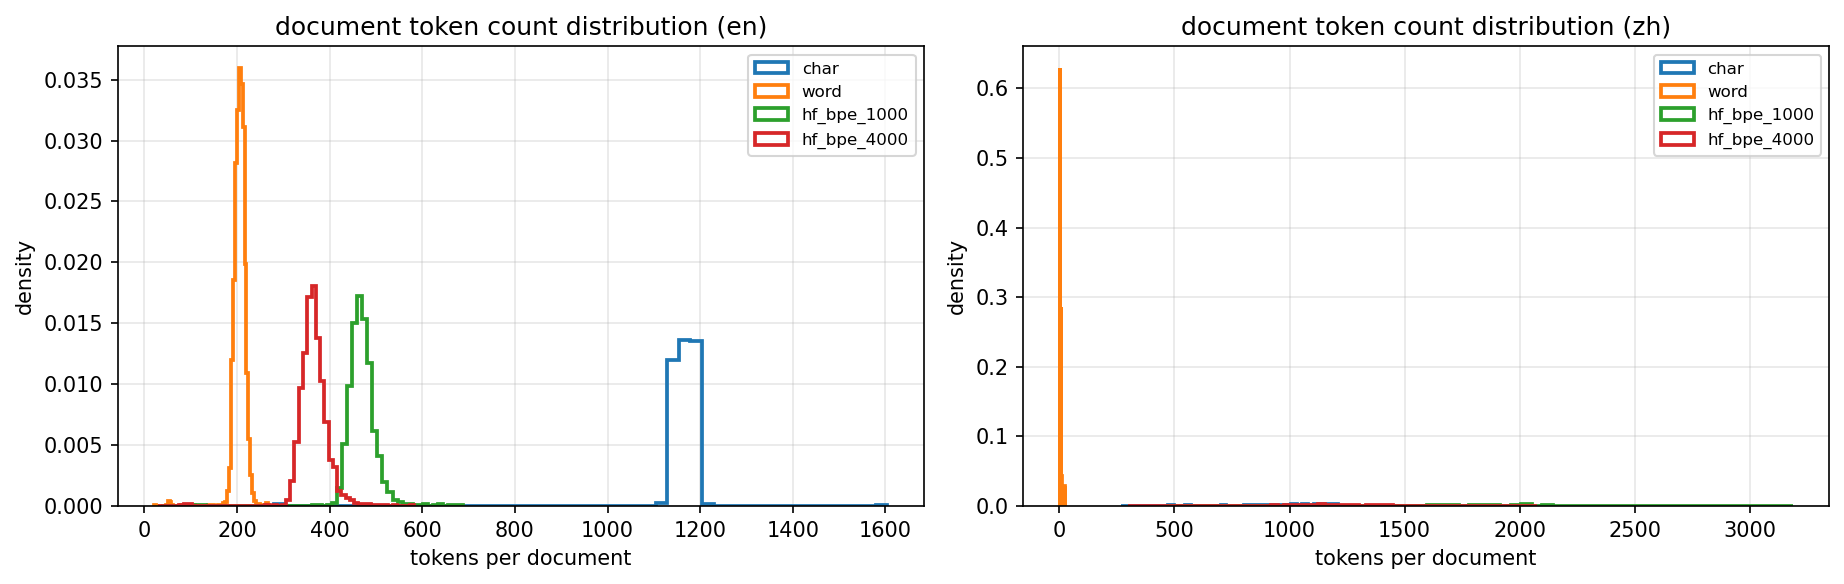

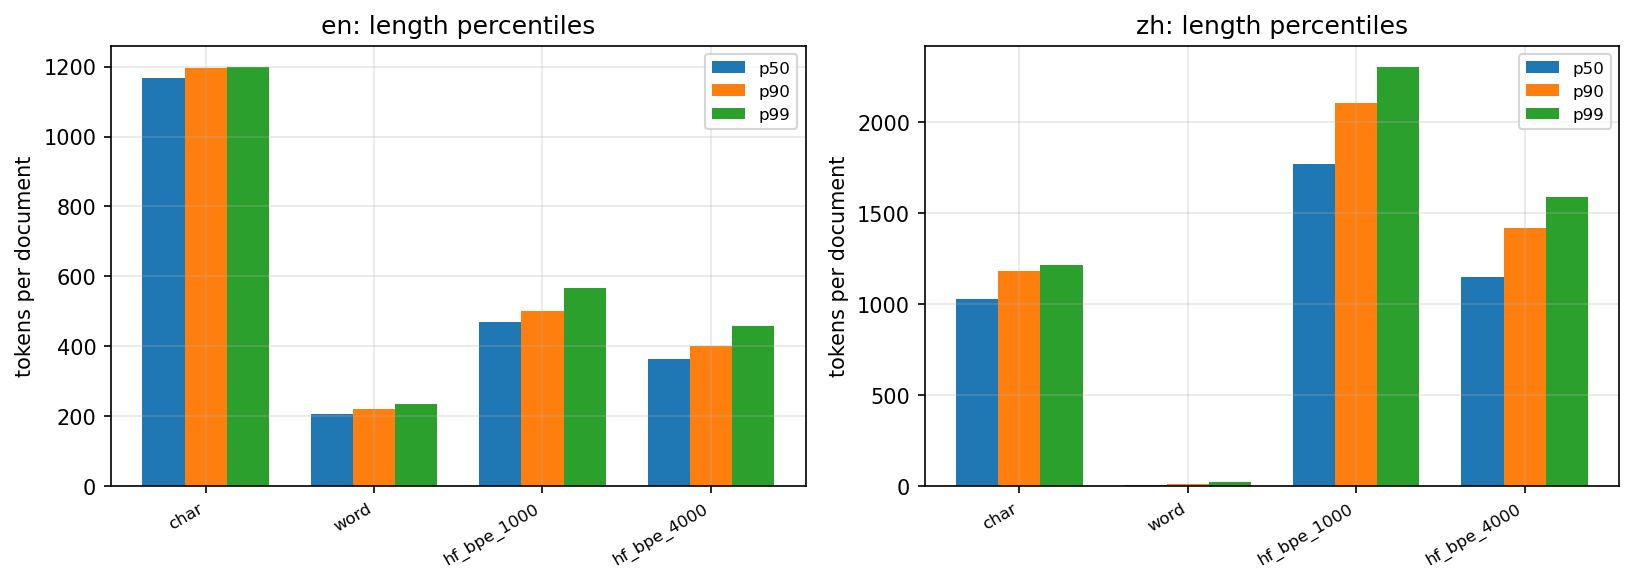

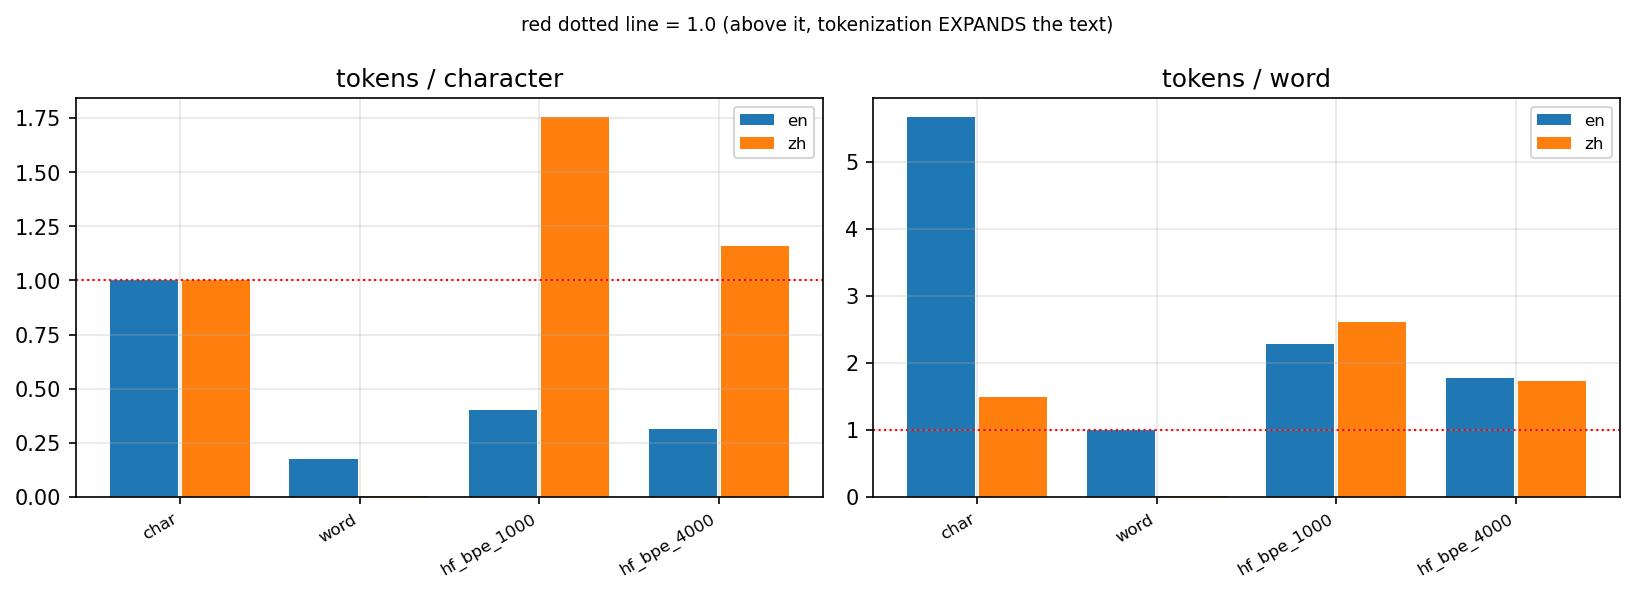

In [3]:
from src import plotting
p = plotting.plot_length_distributions(lengths, [t.name for t in tokenizers]); display(Image(str(p)))
p = plotting.plot_length_percentiles(metrics_df); display(Image(str(p)))
p = plotting.plot_ratios(metrics_df); display(Image(str(p)))

### 观察（先自己写，再对照数据卡第 9 节）
1. 词级基线在中文上发生了什么？为什么 `tokens/word` 会远小于 1？
2. `hf_bpe_1000` 在中文上 `tokens/char > 1` 意味着什么？byte-level 预分词在这里起了什么作用？
3. 英文上 char→word→BPE 的压缩倍数各是多少？p99 长度对下游 batch/padding 成本意味着什么？

把你的答案写进 `notes/failure_analysis.md`。

## 3. 核心代码 #1：Toy BPE（你写）

文件：`src/core_bpe.py`。契约与提示都在 docstring 里，这里只放**手算验收夹具**。

手算例子（BPE 论文 / karpathy 同款）：
```
vocab = {("l","o","w","</w>"):5, ("l","o","w","e","r","</w>"):2,
         ("n","e","w","e","s","t","</w>"):6, ("w","i","d","e","s","t","</w>"):3}
```
- `("e","s")` 与 `("s","t")` 都出现 9 次 → 按字典序 tie-break，第一次 merge 必须是 `("e","s")`。
- 合并后 `("es","t")` 9 次 → 第二次；再后 `("est","</w>")` 9 次 → 第三次。

下面这个 cell 在你实现前会打印 PENDING。

In [4]:
from src.core_bpe import get_stats, merge_vocab, train_bpe, ToyBPE

V = {("l","o","w","</w>"):5, ("l","o","w","e","r","</w>"):2,
     ("n","e","w","e","s","t","</w>"):6, ("w","i","d","e","s","t","</w>"):3}
try:
    stats = get_stats(V)
    print("es count =", stats[("e","s")], " st count =", stats[("s","t")])
    best = min(stats, key=lambda p: (-stats[p], p))
    print("first merge (lexicographic tie-break):", best)
    V2 = merge_vocab(best, V)
    print("newest after merge:", [w for w in V2 if w[0] == "n"])
except NotImplementedError as e:
    print("PENDING:", e)

PENDING: TODO(you): count adjacent symbol pairs, weighted by word frequency


In [5]:
try:
    t0 = time.time()
    tok = train_bpe(train_texts[:400], num_merges=500)
    print(f"trained 500 merges on 400 docs in {time.time()-t0:.1f}s, vocab={tok.vocab_size}")
    sample = train_texts[0]
    enc = tok.encode(sample)
    print("tokens[:24]:", enc[:24])
    print("roundtrip ok:", tok.decode(enc) == sample)
    tok.save(OUTPUTS / "toy_bpe_500.json")
except NotImplementedError as e:
    print("PENDING:", e)

PENDING: TODO(you): the BPE training loop (Algorithm 1)


## 4. merge 预算消融

`num_merges ∈ {500,1000,2000,4000}`。你的 BPE 未实现时用 HF byte-level BPE 作代理（`backend` 列会标明）。
关注：曲线何时变平？中文曲线和英文曲线形状为什么不同？

  sweep num_merges=500    backend=hf_bpe_proxy   vocab=757


  sweep num_merges=1000   backend=hf_bpe_proxy   vocab=1257


  sweep num_merges=2000   backend=hf_bpe_proxy   vocab=2257


  sweep num_merges=4000   backend=hf_bpe_proxy   vocab=4257


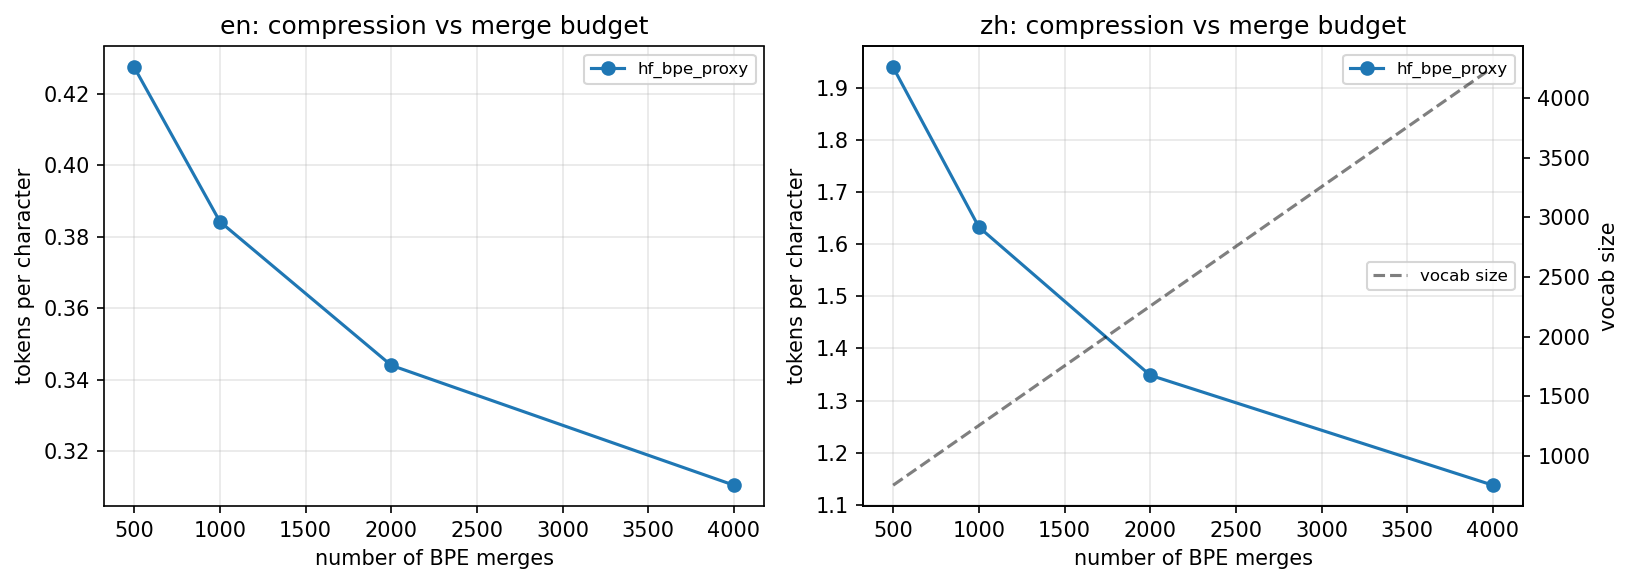

,backend,num_merges,vocab_size,lang,tokens_per_char,tokens_per_word,mean_len,p99_len,unk_rate
0,hf_bpe_proxy,500,757,en,0.427328,2.425591,498.835000,569.01,0.0
1,hf_bpe_proxy,500,757,zh,1.939205,2.887172,1875.754286,2480.82,0.0
2,hf_bpe_proxy,1000,1257,en,0.384185,2.180703,448.472500,519.03,0.0
3,hf_bpe_proxy,1000,1257,zh,1.632938,2.431189,1579.508571,2196.86,0.0
4,hf_bpe_proxy,2000,2257,en,0.344010,1.952663,401.575000,479.02,0.0
5,hf_bpe_proxy,2000,2257,zh,1.348689,2.007986,1304.560000,1821.22,0.0
6,hf_bpe_proxy,4000,4257,en,0.310491,1.762405,362.447500,439.02,0.0
7,hf_bpe_proxy,4000,4257,zh,1.137783,1.693980,1100.554286,1565.40,0.0


In [6]:
from src.run_experiments import merge_sweep
sweep = merge_sweep(train_texts, docs, (500, 1000, 2000, 4000), max_docs=400)
p = plotting.plot_merges_sweep(sweep); display(Image(str(p)))
sweep

## 5. 数据审计：exact + substring（已实现）

三层检测：exact 指纹 → 你的 MinHash/LSH → 探针式子串泄漏。
`data/fixtures/labels.json` 是 ground truth，**审计代码不读它**，只有评分读。

near stage: not_implemented
train dup rate: 1.27% -> 0.00%
test contamination: 6.13% -> 0.00%


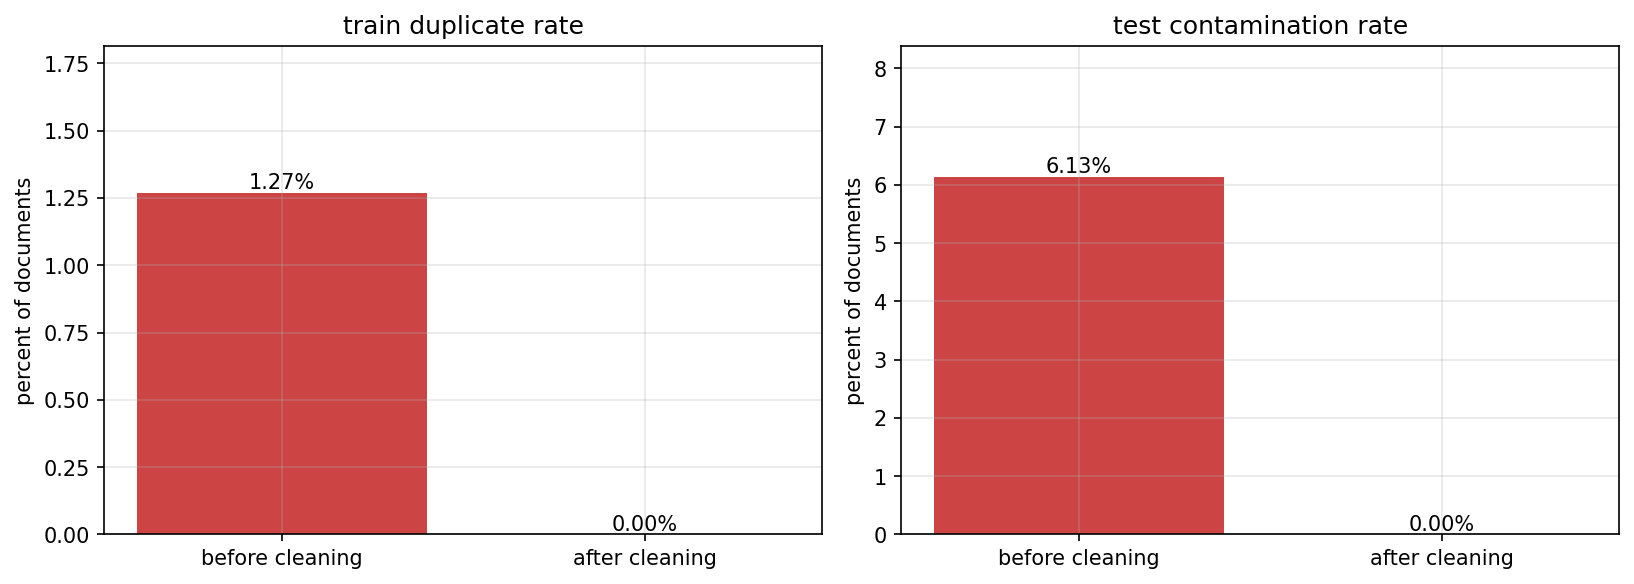

In [7]:
from src.audit_pipeline import AuditConfig, run_audit
cfg = AuditConfig(num_perm=128, bands=32, rows=4, threshold=0.8, enable_near=True)
summary = run_audit(train, test, cfg, OUTPUTS)
print("near stage:", summary["near_stage"]["status"])
print("train dup rate: %.2f%% -> %.2f%%" % (summary["before"]["train_duplicate_rate"]*100, summary["after"]["train_duplicate_rate"]*100))
print("test contamination: %.2f%% -> %.2f%%" % (summary["before"]["test_contamination_rate"]*100, summary["after"]["test_contamination_rate"]*100))
p = plotting.plot_dedup_before_after(summary); display(Image(str(p)))

## 6. 核心代码 #2：MinHash + LSH（你写）

文件：`src/core_minhash.py`。四个阶段：`shingles → build_signatures → lsh_candidate_pairs → verify_pairs`。

**先推导再写代码**：b 个 band、每 band r 行时，Jaccard 为 s 的两篇成为候选的概率是
`P(s) = 1 - (1 - s^r)^b`。取 `num_perm=128, b=32, r=4`，阈值近似 `(1/b)^(1/r) ≈ 0.42`；
再经 `verify_pairs(threshold=0.8)` 精确过滤。下面 cell 会把理论曲线和你实测的 recall/precision 画在一起。

两个最容易踩的坑（docstring 里也写了）：
1. 用内置 `hash()` → 每进程盐不同 → 结果不可复现。用 hashlib 或固定种子。
2. 每个 shingle 算 128 次 hashlib → 6 亿次哈希，跑几十分钟。先算一次 base hash，再做 128 次 `(a*h+b) mod p` 整数运算。

In [8]:
from src import core_minhash as cm
try:
    a = cm.shingles("the quick brown fox jumps", k=5, mode="char")
    b = cm.shingles("the quick brown cat jumps", k=5, mode="char")
    print("jaccard =", round(cm.jaccard(a, b), 4))
    sig = cm.minhash_signature(a, num_perm=128, seed=0)
    sig2 = cm.minhash_signature(a, num_perm=128, seed=0)
    print("len:", len(sig), "deterministic:", list(sig) == list(sig2))
except NotImplementedError as e:
    print("PENDING:", e)

PENDING: TODO(you): k-shingles, char or word mode


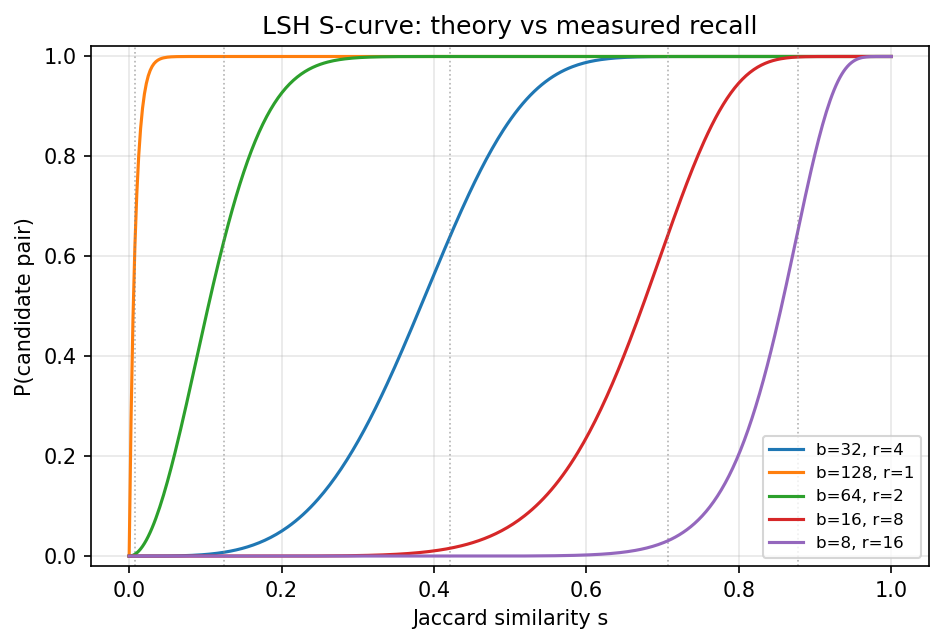

'PENDING: implement src/core_minhash.py'

In [9]:
from src.run_experiments import lsh_threshold_sweep
labels = read_json(ROOT / "data" / "fixtures" / "labels.json")["labels"]
measured = lsh_threshold_sweep(docs, labels, cfg, (0.5, 0.6, 0.7, 0.8, 0.9), sweep_docs=1500)
p = plotting.plot_lsh_scurve([(32, 4), (128, 1), (64, 2), (16, 8), (8, 16)],
                             measured if len(measured) else None)
display(Image(str(p)))
measured if len(measured) else "PENDING: implement src/core_minhash.py" 

## 7. 夹具验收：对给定重复/泄漏样本能检测出来吗

In [10]:
from src.report import score_audit
scores = score_audit(OUTPUTS / "data_audit.csv")
rows = []
for kind, v in scores["per_kind"].items():
    rows.append([kind, v["expected"], v["detected"],
                 f"{v['recall']*100:.1f}%" if "recall" in v else f"FP={v.get('false_positives', 0)}"])
pd.DataFrame(rows, columns=["fixture", "expected", "detected", "recall / FP"])

,fixture,expected,detected,recall / FP
0,exact_dup_train,40,40,100.0%
1,near_dup_train,36,0,0.0%
2,boilerplate_trap,12,0,FP=0
3,leak_exact,20,20,100.0%
4,leak_near,15,14,93.3%
5,leak_span,15,15,100.0%


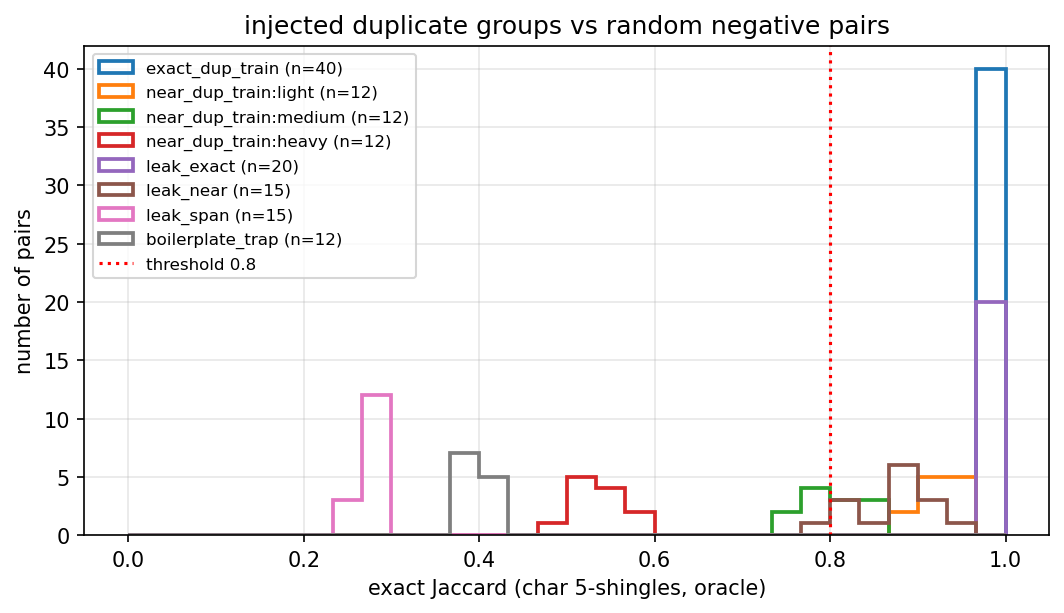

In [11]:
groups = {}
for v in labels.values():
    s = v.get("oracle_jaccard_char5")
    if s is None:
        continue
    key = f"{v['kind']}:{v.get('level', '')}" if v["kind"] == "near_dup_train" else v["kind"]
    groups.setdefault(key, []).append(s)
p = plotting.plot_similarity_distribution(groups); display(Image(str(p)))

验收线（建议，写进你的提交说明）：
- exact_dup_train / leak_exact / leak_span 召回 = 100%
- near_dup light+medium 召回 ≥ 90%，heavy 允许漏（Jaccard 已低于阈值，属于方法边界而非 bug）
- boilerplate_trap 与 control 误报 = 0
达不到时，先定位是哪一层丢的：签名？分桶？验证阈值？

## 8. Stretch：中英混合的 token/字 与 token/词 比值

In [12]:
zh = metrics_df[metrics_df.lang == "zh"][["tokenizer", "tokens_per_char", "tokens_per_word", "unk_rate"]]
en = metrics_df[metrics_df.lang == "en"][["tokenizer", "tokens_per_char", "tokens_per_word", "unk_rate"]]
print("EN"); print(en.to_string(index=False))
print("ZH"); print(zh.to_string(index=False))

EN
  tokenizer  tokens_per_char  tokens_per_word  unk_rate
       char         1.000000         5.664711   0.00000
       word         0.176531         1.000000   0.01099
hf_bpe_1000         0.403336         2.284784   0.00000
hf_bpe_4000         0.314061         1.779063   0.00000
ZH
  tokenizer  tokens_per_char  tokens_per_word  unk_rate
       char         1.000000         1.488843  0.001477
       word         0.004850         0.007221  0.197320
hf_bpe_1000         1.753607         2.610845  0.000000
hf_bpe_4000         1.158873         1.725379  0.000000


讨论：为什么同一套 BPE 在两种语言上的压缩方向相反？
如果要把中英混合语料喂给一个模型，词表预算应该怎么分配？（提示：看每语言的字符占比与 tokens/char。）

## 9. 失败分析（必填，提交内容之一）

在 `notes/failure_analysis.md` 里至少写 4 条，每条包含：**现象 → 定位 → 根因 → 修复或边界说明**。
候选线索（不要只抄，要自己复现并给数字）：
1. 词级切分在中文上的崩溃（UNK 率、tokens/word）。
2. 小词表 byte-level BPE 对中文的膨胀（tokens/char > 1）。
3. leak_span 为什么文档级 MinHash 检不出（Jaccard 0.26–0.30 vs 阈值 0.8）。
4. 探针式子串检测漏掉的那 1 篇 leak_near（看 `acceptance_scores.csv` 的 missed_ids）。
5. boilerplate 陷阱在低阈值下的误报。
6. 你的 BPE 在中文预分词上的选择带来的后果。

## 10. 我的问题（必填，提交内容之一）

模板：
- 我还没弄懂的概念是……（例如：MinHash 为什么能用最小哈希估计 Jaccard？证明思路是什么？）
- 我的实现与论文不一致的地方是……，我选择这样做的理由是……
- 如果语料换成代码/对话数据，我预期哪些结论会失效？
- 下一步（Week 2 char-LM）我想验证的假设是……

## 11. 数据卡与提交清单

In [13]:
from src.report import write_data_card
card = write_data_card(metrics_df, summary, scores, OUTPUTS / "data_card.md")
print("data card ->", card)
print(f"peak RSS: {peak_memory_mb():.0f} MB (budget < 2048 MB)")
print('''
提交清单:
  [ ] notebooks/tokenizer_demo.ipynb  (本文件, 全部 cell 有输出)
  [ ] outputs/data_audit.csv          (逐文档审计结果)
  [ ] outputs/data_card.md            (数据卡)
  [ ] outputs/figures/*.png           (8 张结果图)
  [ ] outputs/metrics.csv / merges_sweep.csv / lsh_sweep.csv / acceptance_scores.csv
  [ ] notes/failure_analysis.md       (失败分析)
  [ ] notes/paper_bpe.md / paper_dedup.md (精读四问)
  [ ] README.md 中的运行命令与对照实验说明
''')

data card -> D:\python\LLM\01_toy_bpe_data_audit\outputs\data_card.md
peak RSS: 355 MB (budget < 2048 MB)

提交清单:
  [ ] notebooks/tokenizer_demo.ipynb  (本文件, 全部 cell 有输出)
  [ ] outputs/data_audit.csv          (逐文档审计结果)
  [ ] outputs/data_card.md            (数据卡)
  [ ] outputs/figures/*.png           (8 张结果图)
  [ ] outputs/metrics.csv / merges_sweep.csv / lsh_sweep.csv / acceptance_scores.csv
  [ ] notes/failure_analysis.md       (失败分析)
  [ ] notes/paper_bpe.md / paper_dedup.md (精读四问)
  [ ] README.md 中的运行命令与对照实验说明

